<a href="https://colab.research.google.com/github/Razibfauzi/simulasi-kecepatan-motor/blob/main/Simulasi_Kecepatan_Motor.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Pemodelan dan Simulasi Sistem Dinamik: Kecepatan Sepeda Motor dengan Hambatan Udara

Mata kuliah: Pemodelan Sistem Dinamik

**Model:**

$m\,\dfrac{dv}{dt} = c\,u - \tfrac{1}{2}\rho C_d A v^2 - C_{rr} m g$ , $\quad \dfrac{dx}{dt}=v$

Keterangan: $u$ = bukaan gas (%), $v$ = kecepatan (m/s), $x$ = jarak tempuh (m).

In [33]:
!pip install gekko -q

## 1. Import library

In [34]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint

## 2. Parameter sistem

In [35]:
# ---------- Parameter ----------
m   = 170.0   # massa motor + pengendara (kg)
c   = 2.0     # konstanta gaya dorong (N per % bukaan gas)
rho = 1.2     # massa jenis udara (kg/m^3)
Cd  = 0.7     # koefisien hambat aerodinamis
A   = 0.6     # luas frontal (m^2)
Crr = 0.015   # koefisien hambatan gelinding
g   = 9.81    # percepatan gravitasi (m/s^2)


## 3. Model sistem dinamik (fungsi turunan)

In [36]:
# ---------- Model ----------
def motor(z, t, u, Cd=Cd):
    v, x = z
    F_dorong = c * u                       # gaya dorong mesin (N)
    F_udara  = 0.5 * rho * Cd * A * v**2   # gaya hambat udara (N)
    F_roda   = Crr * m * g                 # hambatan gelinding (N)
    dvdt = (F_dorong - F_udara - F_roda) / m
    if v <= 0 and dvdt < 0:                # motor diam tidak bergerak mundur
        dvdt = 0.0
    dxdt = v
    return [dvdt, dxdt]


## 4. Waktu dan input bukaan gas
Gas 0% (0-5 s), 50% (5-50 s), 100% (50-100 s), lalu dilepas 0% (100-150 s).

In [37]:
# ---------- Waktu & input bukaan gas ----------
ts = np.linspace(0, 150, 1501)             # 0-150 s, setiap 0.1 s
u = np.zeros(1501)
u[50:500]   = 50.0                         # 5 s - 50 s  : gas 50%
u[500:1000] = 100.0                        # 50 s - 100 s: gas 100%
                                           # 100 s - 150 s: gas dilepas (0%)


## 5. Simulasi dengan `odeint`

In [38]:
# ---------- Simulasi ----------
z0 = [0.0, 0.0]                            # v(0)=0 m/s, x(0)=0 m
v = np.zeros(1501)
x = np.zeros(1501)
for i in range(1500):
    y = odeint(motor, z0, [0, 0.1], args=(u[i],))
    z0 = y[-1]
    v[i + 1], x[i + 1] = z0


## 6. Grafik hasil simulasi

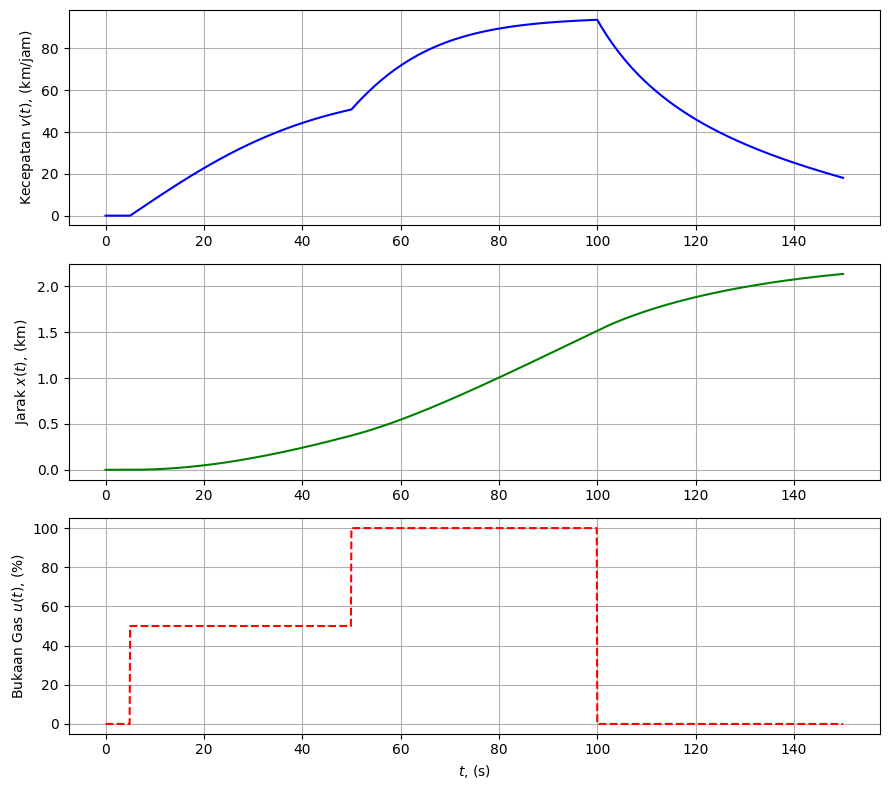

In [39]:
import os
os.makedirs('gambar', exist_ok=True)
# ---------- Plot ----------
plt.figure(figsize=(9, 8))
plt.subplot(3, 1, 1)
plt.plot(ts, v * 3.6, 'b-')
plt.ylabel('Kecepatan $v(t)$, (km/jam)'); plt.grid(True)
plt.subplot(3, 1, 2)
plt.plot(ts, x / 1000, 'g-')
plt.ylabel('Jarak $x(t)$, (km)'); plt.grid(True)
plt.subplot(3, 1, 3)
plt.plot(ts, u, 'r--')
plt.ylabel('Bukaan Gas $u(t)$, (%)'); plt.xlabel('$t$, (s)'); plt.grid(True)
plt.tight_layout()
plt.savefig('gambar/grafik1_simulasi_utama.png', dpi=150)
plt.show()


## 7. Kecepatan steady state (analitik) dan ringkasan hasil

In [40]:
# ---------- Kecepatan steady state (hitungan analitik) ----------
for ub in (50, 100):
    vss = np.sqrt((c * ub - Crr * m * g) / (0.5 * rho * Cd * A))
    print(f'u = {ub}% -> v_ss = {vss:.2f} m/s = {vss*3.6:.1f} km/jam')
print(f'Kecepatan pada t=50 s : {v[500]*3.6:.1f} km/jam')
print(f'Kecepatan pada t=100 s: {v[1000]*3.6:.1f} km/jam')
print(f'Kecepatan pada t=150 s: {v[1500]*3.6:.1f} km/jam')
print(f'Jarak total           : {x[-1]/1000:.2f} km')


u = 50% -> v_ss = 17.25 m/s = 62.1 km/jam
u = 100% -> v_ss = 26.35 m/s = 94.9 km/jam
Kecepatan pada t=50 s : 50.8 km/jam
Kecepatan pada t=100 s: 93.7 km/jam
Kecepatan pada t=150 s: 18.1 km/jam
Jarak total           : 2.13 km


## 8. Pengaruh koefisien hambat $C_d$ (gas 100% tetap)

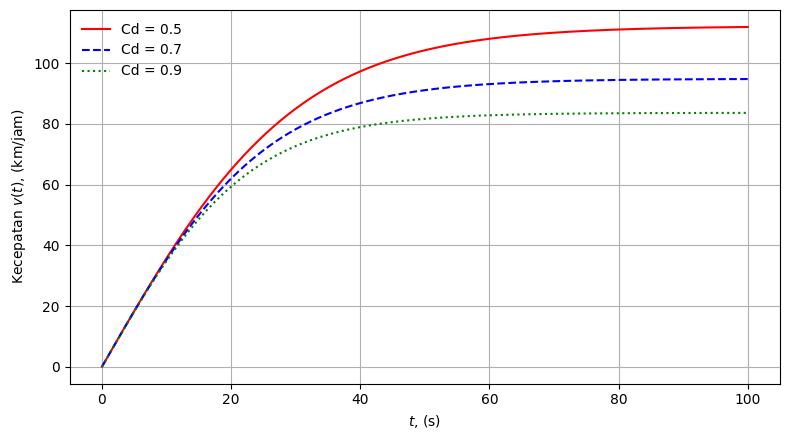

In [41]:
# ---------- Pengaruh koefisien hambat Cd (gas 100% tetap) ----------
ts2 = np.linspace(0, 100, 1001)
plt.figure(figsize=(8, 4.5))
for Cd_var, gaya, lbl in [(0.5, 'r-', 'Cd = 0.5'), (0.7, 'b--', 'Cd = 0.7'), (0.9, 'g:', 'Cd = 0.9')]:
    sol = odeint(motor, [0, 0], ts2, args=(100.0, Cd_var))
    plt.plot(ts2, sol[:, 0] * 3.6, gaya, label=lbl)
plt.xlabel('$t$, (s)'); plt.ylabel('Kecepatan $v(t)$, (km/jam)')
plt.legend(frameon=False); plt.grid(True); plt.tight_layout()
plt.savefig('gambar/grafik2_variasi_Cd.png', dpi=150)
plt.show()

np.save('hasil_odeint.npy', np.vstack([ts, v, x, u]))


## 9. Simulasi dengan GEKKO
Persamaan yang sama diselesaikan dengan GEKKO (IMODE=4) lalu dibandingkan dengan `odeint`.

/tmp/ipykernel_1953/143753986.py:27: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  plt.plot(m.time, np.array(v.value) * 3.6, 'b-')


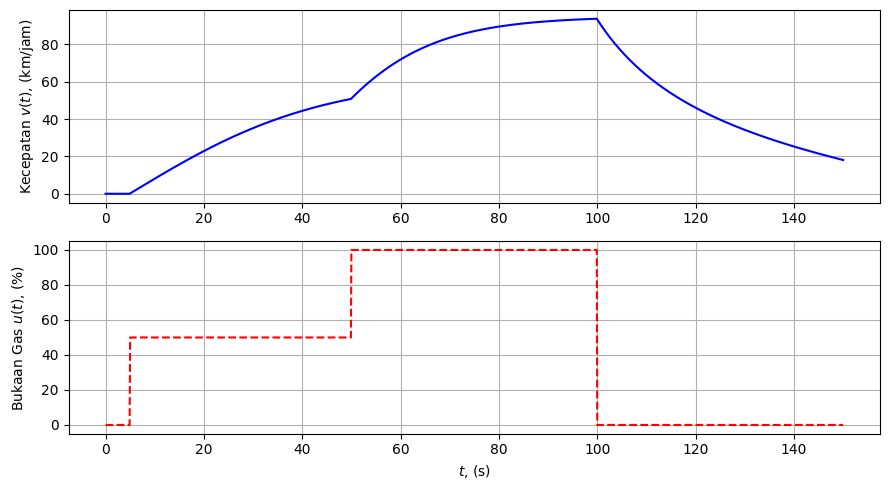

Selisih maksimum v (GEKKO vs odeint): 0.1187 m/s


/tmp/ipykernel_1953/143753986.py:39: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  selisih = np.max(np.abs(hasil[1] - np.array(v.value)))


In [42]:
import numpy as np
import matplotlib.pyplot as plt
from gekko import GEKKO

m_, c, rho, Cd, A, Crr, g = 170.0, 2.0, 1.2, 0.7, 0.6, 0.015, 9.81

m = GEKKO(remote=False)
ts = np.linspace(0, 150, 1501)
m.time = ts

ustep = np.zeros(1501)
ustep[50:500]   = 50.0
ustep[500:1000] = 100.0
u = m.Param(value=ustep)                   # bukaan gas (%)

v = m.Var(0.0)                             # kecepatan (m/s)
x = m.Var(0.0)                             # jarak (m)
k = 0.5 * rho * Cd * A
m.Equation(m_ * v.dt() == c * u - k * v**2 - Crr * m_ * g * m.tanh(v / 0.05))
m.Equation(x.dt() == v)

m.options.IMODE = 4
m.solve(disp=False)

plt.figure(figsize=(9, 5))
plt.subplot(2, 1, 1)
plt.plot(m.time, np.array(v.value) * 3.6, 'b-')
plt.ylabel('Kecepatan $v(t)$, (km/jam)'); plt.grid(True)
plt.subplot(2, 1, 2)
plt.plot(m.time, u.value, 'r--')
plt.ylabel('Bukaan Gas $u(t)$, (%)'); plt.xlabel('$t$, (s)'); plt.grid(True)
plt.tight_layout()
plt.savefig('gambar/grafik3_gekko.png', dpi=150)
plt.show()

# Bandingkan dengan hasil odeint
try:
    hasil = np.load('hasil_odeint.npy')
    selisih = np.max(np.abs(hasil[1] - np.array(v.value)))
    print(f'Selisih maksimum v (GEKKO vs odeint): {selisih:.4f} m/s')
except FileNotFoundError:
    print('Jalankan simulasi_odeint.py dahulu untuk membandingkan hasil.')
